# Feedstock application across GCAM regions
SCEPTER receives feedstock in terms of t/ha/year. GCAM reports the mass of rock spread in each region per year. For this script, we look at amendments where we convert to t/ha/year based on two rules: 
1. A fixed application rate is selected, and the cropland area required to match the GCAM number is what varies.
2. If the required cropland area exceeds the available area, we up the fixed application rate until we hit the GCAM number. 

This script plots feedstock application outcomes across fixed application rates and GCAM scenarios.

## Distributing rock over time
A fixed application rate over time (and varying area) assumes that the earliest sites continue doing ERW the longest. Those sites benefit from high, maintained application more likely to overcome pH buffering quickly. In reality, we expect many early stage sites to turn on and off over time (e.g., with contracting cycles and startup capacity), causing lower time-averaged application rates that may look more like holding the area fixed and varying the application amount. 

The point is not to predict the future, it's to illustrate that these dynamics matter for long-term ERW outcomes at scale. 

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import os

# --- read in data 
DEG_RESOLUTION = 1
scenarios = ["exe_central1p5", "exe_noWeathering1p5", "exe_techBehaviorChange1p5"]
app_rates = np.array([5, 7.5, 10, 15, 20, 30, 40, 50])
gcam_fn    = f'cropland+gcamRegions_time_{DEG_RESOLUTION}deg.zarr'
gcam_fn_df = f'annual_rockflx_densest-ag-region_{DEG_RESOLUTION}deg.pkl'

pkl_cols = ["cropland_area_required_ha", "cropland_fraction_required", "cropland_fraction_effective"]

# loop through scenarios and app rates, building a dataset with
# app_rate and scenario as dimensions
ds_list_scen = []
df_by_scen_ar = {}   # {scen: {apprate: df}}
for scen in scenarios:
    ds_list_ar = []
    df_by_scen_ar[scen] = {}
    for apprate in app_rates:
        gcam_dir = f"s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/{scen}/{apprate}-tHaYr-appRate"
        ds_ar = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))
        ds_ar = ds_ar.expand_dims({"app_rate": [apprate], "scenario": [scen]})
        ds_list_ar.append(ds_ar)
        df_by_scen_ar[scen][apprate] = pd.read_pickle(os.path.join(gcam_dir, gcam_fn_df))
    ds_list_scen.append(xr.concat(ds_list_ar, dim="app_rate"))

ds = xr.concat(ds_list_scen, dim="scenario")

# --- build ds_regs: pkl columns as (app_rate, scenario, time, reg_id) DataArrays
# stored separately from ds because reg_id is already a spatial (y,x) variable there
_sample_df = df_by_scen_ar[scenarios[0]][app_rates[0]]
_reg_ids = np.sort(_sample_df["reg_id"].unique())
_times   = np.sort(_sample_df["time"].unique())

data_vars = {}
for col in pkl_cols:
    arr = np.full((len(app_rates), len(scenarios), len(_times), len(_reg_ids)), np.nan)
    for i_ar, apprate in enumerate(app_rates):
        for i_sc, scen in enumerate(scenarios):
            pivot = (
                df_by_scen_ar[scen][apprate]
                .pivot(index="time", columns="reg_id", values=col)
                .reindex(index=_times, columns=_reg_ids)
            )
            arr[i_ar, i_sc] = pivot.values
    data_vars[col] = xr.DataArray(
        arr,
        dims=["app_rate", "scenario", "time", "reg_id"],
        coords={"app_rate": app_rates, "scenario": scenarios, "time": _times, "reg_id": _reg_ids},
    )

ds_regs = xr.Dataset(data_vars)
# ds, ds_regs

In [9]:
ds

<xarray.Dataset> Size: 3GB
Dimensions:                  (app_rate: 8, scenario: 3, y: 180, x: 360, time: 81)
Coordinates:
  * app_rate                 (app_rate) float64 64B 5.0 7.5 10.0 ... 40.0 50.0
  * scenario                 (scenario) object 24B 'exe_central1p5' ... 'exe_...
  * y                        (y) float64 1kB 89.5 88.5 87.5 ... -88.5 -89.5
  * x                        (x) float64 3kB -179.5 -178.5 ... 178.5 179.5
  * time                     (time) int64 648B 2020 2021 2022 ... 2098 2099 2100
    spatial_ref              int64 8B 0
Data variables:
    cell_area_m              (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_area            (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_area_by_region  (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_frac            (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    frac_regional_cropland   (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    reg_id                   (app_rate, scenario, y, x) int32 6MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    rockflx_Mt               (app_rate, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 21, 45, 90), meta=np.ndarray>
    rockflx_Mt_ha            (app_rate, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 21, 45, 90), meta=np.ndarray>
    rockflx_t_ha             (app_rate, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 21, 45, 90), meta=np.ndarray>
    cropland_frac_plot       (app_rate, scenario, y, x) float64 12MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>

## Cropland fraction in global grid cells

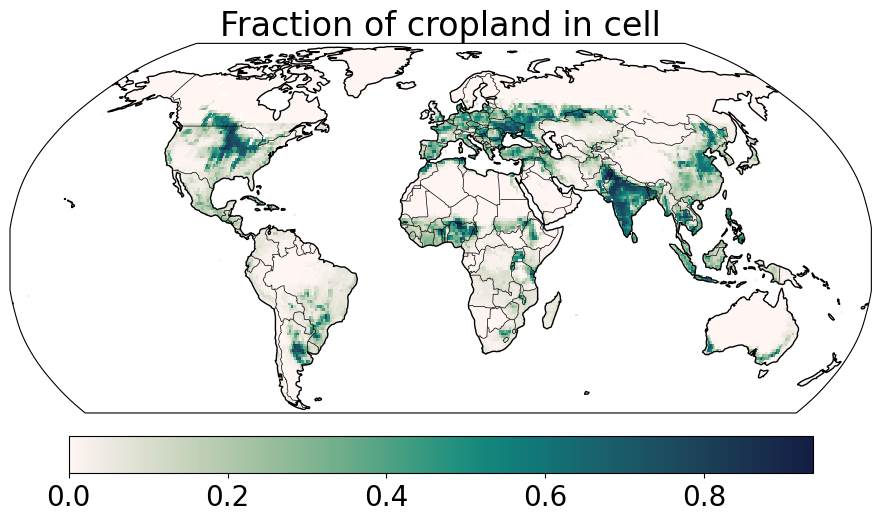

In [10]:
# ---------------------------------
# [ aesthetics ]
# color
mycmap = cmo.cm.tempo
# fonts
fs_title = 24
fs_legend_tick = 20
fs_legend_title= 20 
# extent
lon_min = -181
lon_max = 181
lat_min = -57
lat_max = 86
# ---------------------------------
# --- remove ocean cells
ds['cropland_frac_plot'] = ds['cropland_frac'].where(ds['cropland_area_by_region'] != 0, other=np.nan)

# --- [ PLOT ]
# cropland_frac is a static geographic field — select one slice to get a 2D (lat, lon) array
da = ds['cropland_frac_plot'].isel(scenario=0, app_rate=0)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot (important: specify transform!)
im = da.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),  # data are lat/lon
    cmap= mycmap,
    add_colorbar=True,
    cbar_kwargs={
        "orientation": "horizontal",
        "pad": 0.05,        # distance from plot
        "shrink": 0.8       # optional: make shorter
    }
)
# colorbar text
cbar = im.colorbar
cbar.ax.tick_params(labelsize=fs_legend_tick)
cbar.set_label("", fontsize=fs_legend_title)
# extent + coasts
ax.set_extent([lon_min, lon_max, lat_min, lat_max],
              crs=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
# ax.set_global()
plt.title("Fraction of cropland in cell", fontsize= fs_title)
plt.show()

## Regional mean application rate map across scenarios and crop fractions
Using the fixed regional number across the entire gcam region (no NaNs).

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_22022/2805706096.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


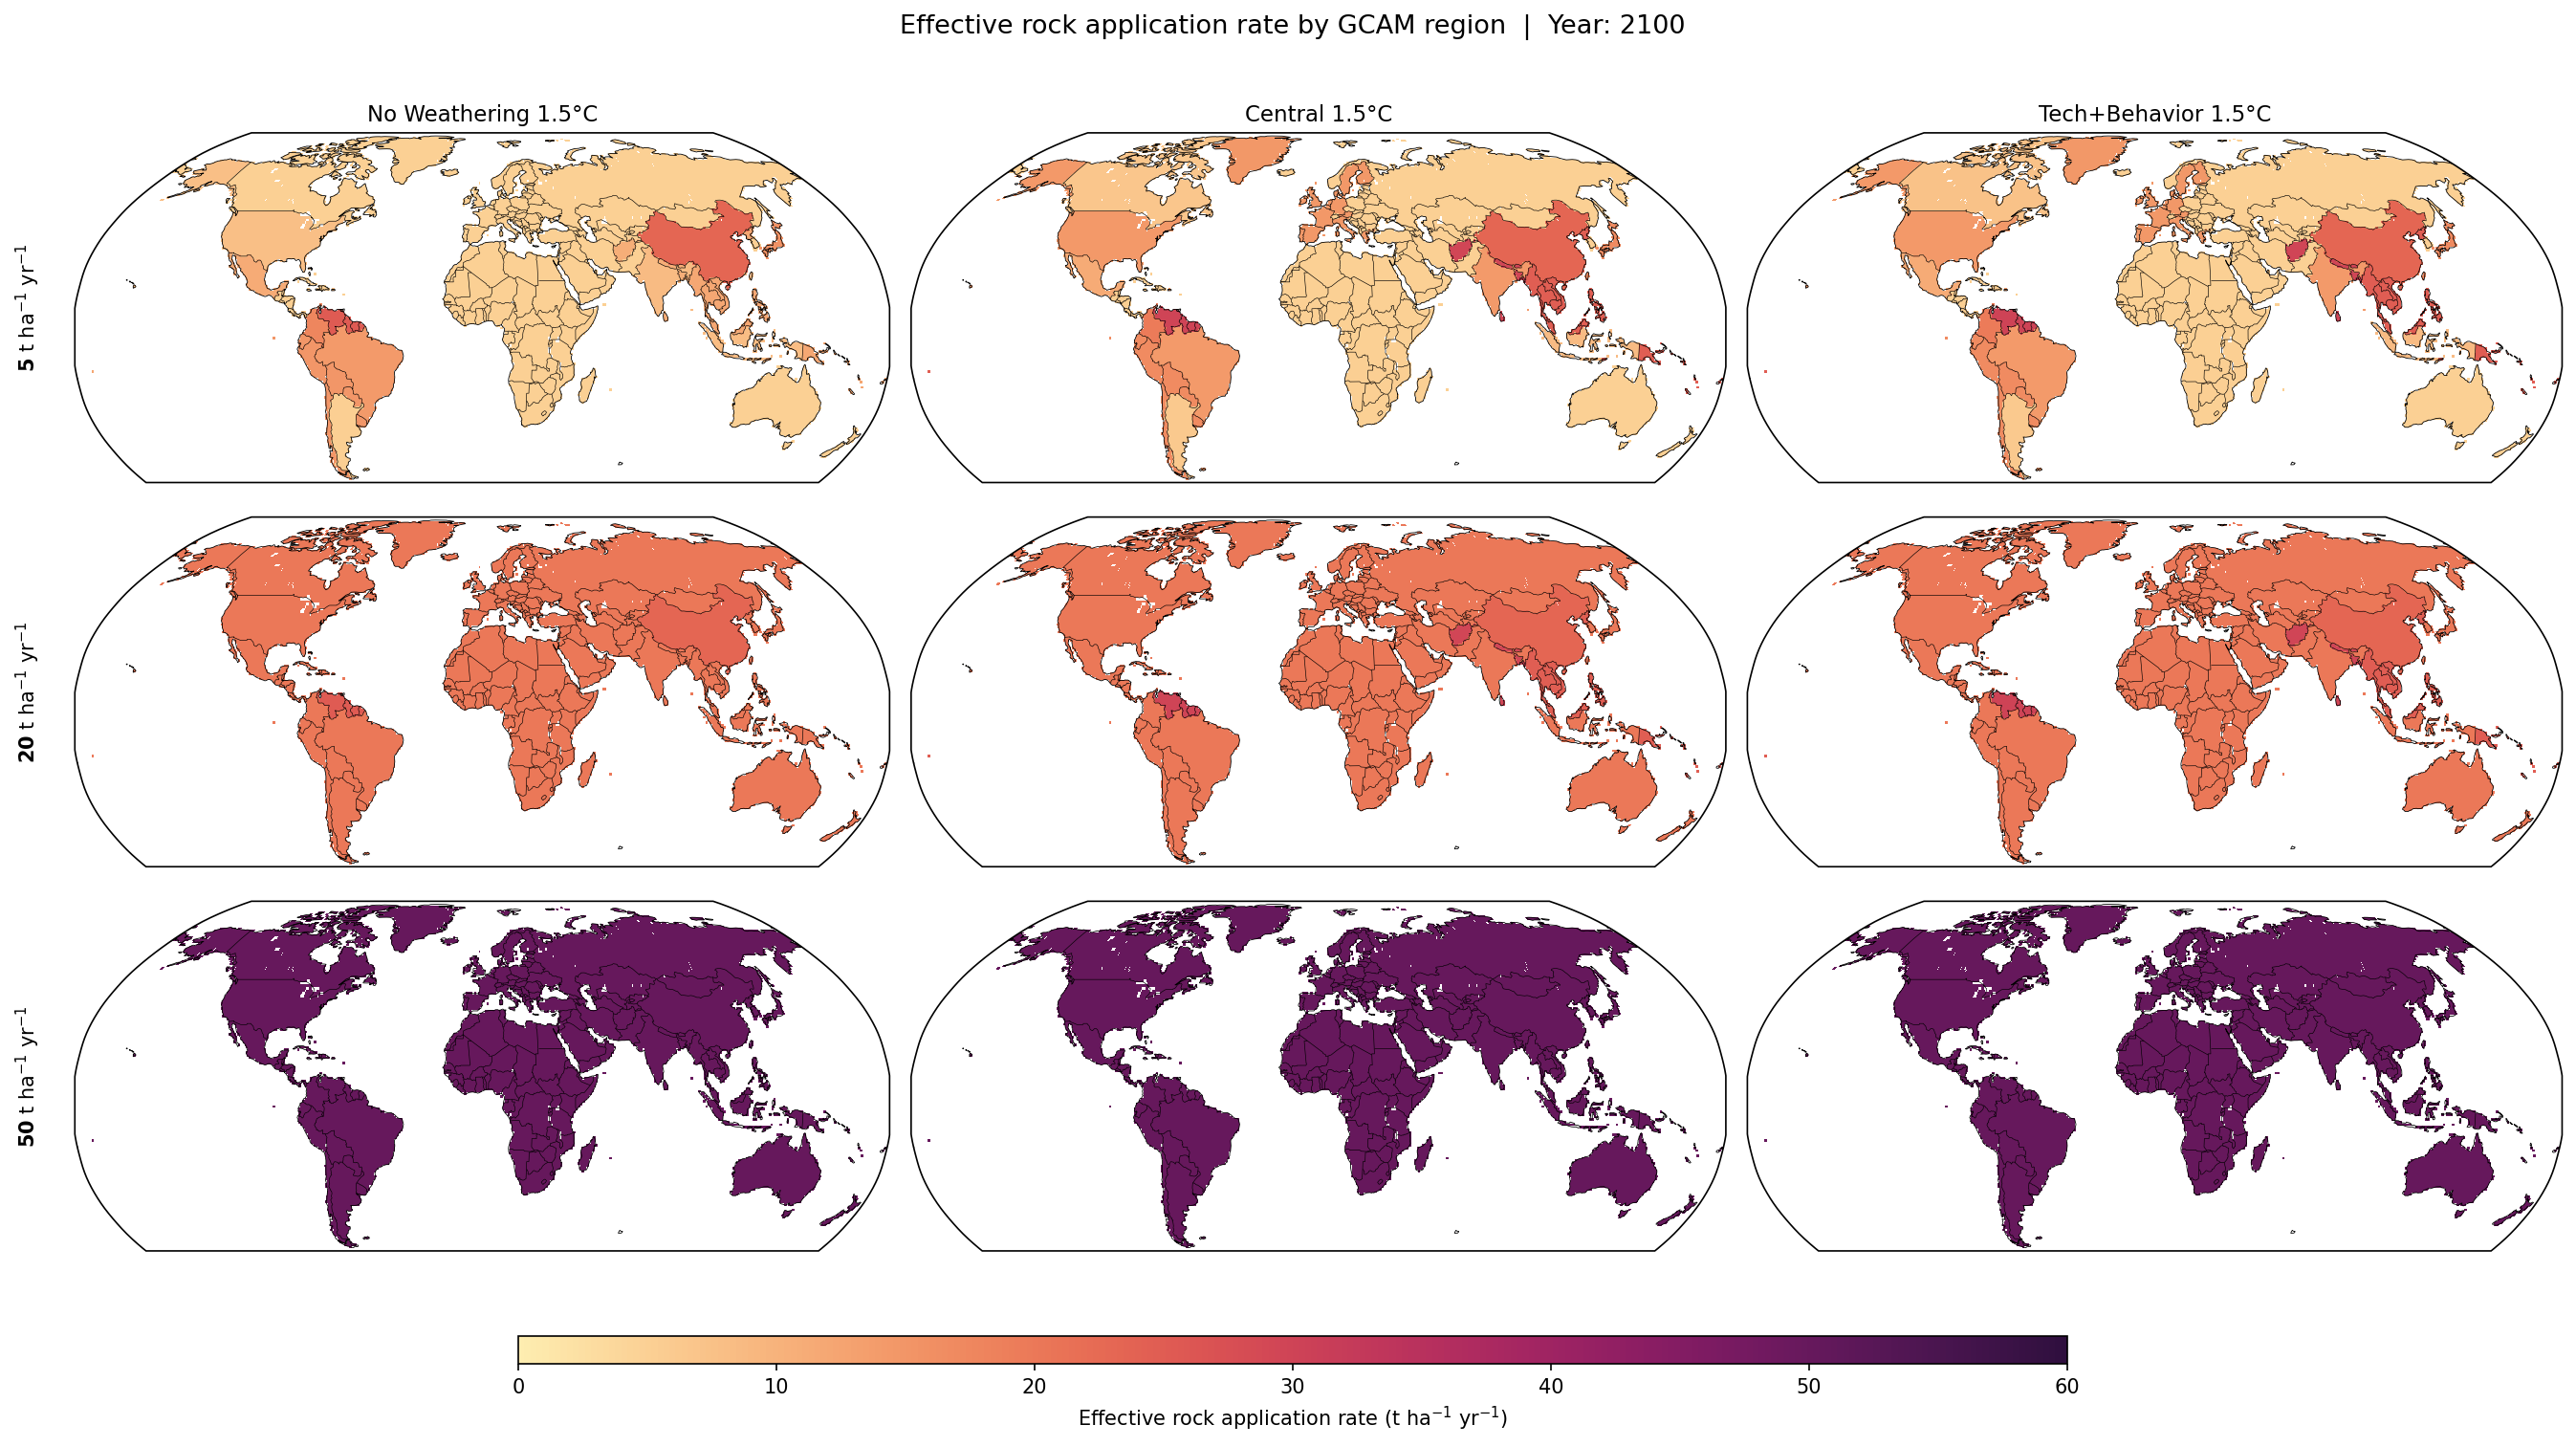

In [14]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
grid_scenarios  = [          # 3 scenarios → 3 columns
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
grid_app_rates  = [5, 20, 50]   # 3 app rates → 3 rows
grid_year       = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_grid  = cmo.cm.matter
vmin_grid    = 0
vmax_grid    = 60
fs_col_title = 11
fs_row_label = 10
fs_cbar_tick = 10
fs_cbar_label= 10
fig_dpi      = 150

lon_min_grid = -181;  lon_max_grid = 181
lat_min_grid =  -57;  lat_max_grid =  86

scen_labels = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ helper: broadcast each region's rockflx_t_ha to all its cells ]
# rockflx_t_ha is NaN outside cropland even though reg_id covers the
# full land area — take the nanmean per region and paint it onto every
# cell sharing that reg_id so the map shows solid regional blocks.
# ============================================================
reg_ids_np  = ds["reg_id"].isel(scenario=0, app_rate=0).values  # (y, x)
unique_regs = np.unique(reg_ids_np[reg_ids_np > 0])

def fill_by_region(da):
    vals   = da.values  # (y, x)
    filled = np.full_like(vals, np.nan)
    for reg in unique_regs:
        mask = reg_ids_np == reg
        val  = np.nanmean(vals[mask])
        if np.isfinite(val):
            filled[mask] = val
    return xr.DataArray(filled, dims=["y", "x"], coords={"y": da.y, "x": da.x})

# ============================================================
# [ plot — full GCAM regions (not just cropland cells) ]
# ============================================================
nrows = len(grid_app_rates)
ncols = len(grid_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi,
)

for row, apprate in enumerate(grid_app_rates):
    for col, scen in enumerate(grid_scenarios):
        ax = axes[row, col]

        da_raw = (
            ds["rockflx_t_ha"]
            .sel(scenario=scen, app_rate=apprate, time=grid_year)
        )
        da = fill_by_region(da_raw)

        da.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_grid,
            vmin=vmin_grid,
            vmax=vmax_grid,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_grid, lon_max_grid, lat_min_grid, lat_max_grid],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels.get(scen, scen), fontsize=fs_col_title, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5, r"$\bf{" + str(int(apprate) if apprate == int(apprate) else apprate) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                transform=ax.transAxes,
                fontsize=fs_row_label,
                va="center", ha="right", rotation=90,
            )

# shared colorbar below all panels
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(
    cmap=mycmap_grid,
    norm=mcolors.Normalize(vmin=vmin_grid, vmax=vmax_grid),
)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick)
cbar.set_label(r"Effective rock application rate (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_cbar_label)

fig.suptitle(f"Effective rock application rate by GCAM region  |  Year: {grid_year}",
             fontsize=fs_col_title + 2, y=1.01)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Cropland fraction required by region

For a fixed application rate, `cropland_fraction_required` is the fraction of each region's total cropland that must be treated to hit the GCAM-derived rock flux target. Values > 1 mean the target cannot be met at that rate across the available cropland — those regions have their rate automatically boosted so that applying to 100% of cropland delivers the required total mass.

In [15]:
# ============================================================
# [ helper: paint per-region scalar values onto the 2D pixel grid ]
# reg_ids_np defined in the application rate map cell above
# ============================================================
def paint_regions(values_by_regid, reg_id_grid):
    out = np.full(reg_id_grid.shape, np.nan)
    for rid, val in values_by_regid.items():
        out[reg_id_grid == rid] = val
    return out

# --- total cropland area per region [ha] — used for CDF area-weighting below
_cropland_area_np = ds["cropland_area"].isel(scenario=0, app_rate=0).values  # (y, x) in m²
_reg_id_flat_s    = reg_ids_np.flatten()
_cropland_ha_flat = (_cropland_area_np / 1e4).flatten()
_reg_area_ha      = np.array([
    np.nansum(_cropland_ha_flat[_reg_id_flat_s == rid])
    for rid in ds_regs.reg_id.values
])
_total_global_cropland_ha = _reg_area_ha.sum()
print("Setup complete")

Setup complete


/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_22022/3768388367.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


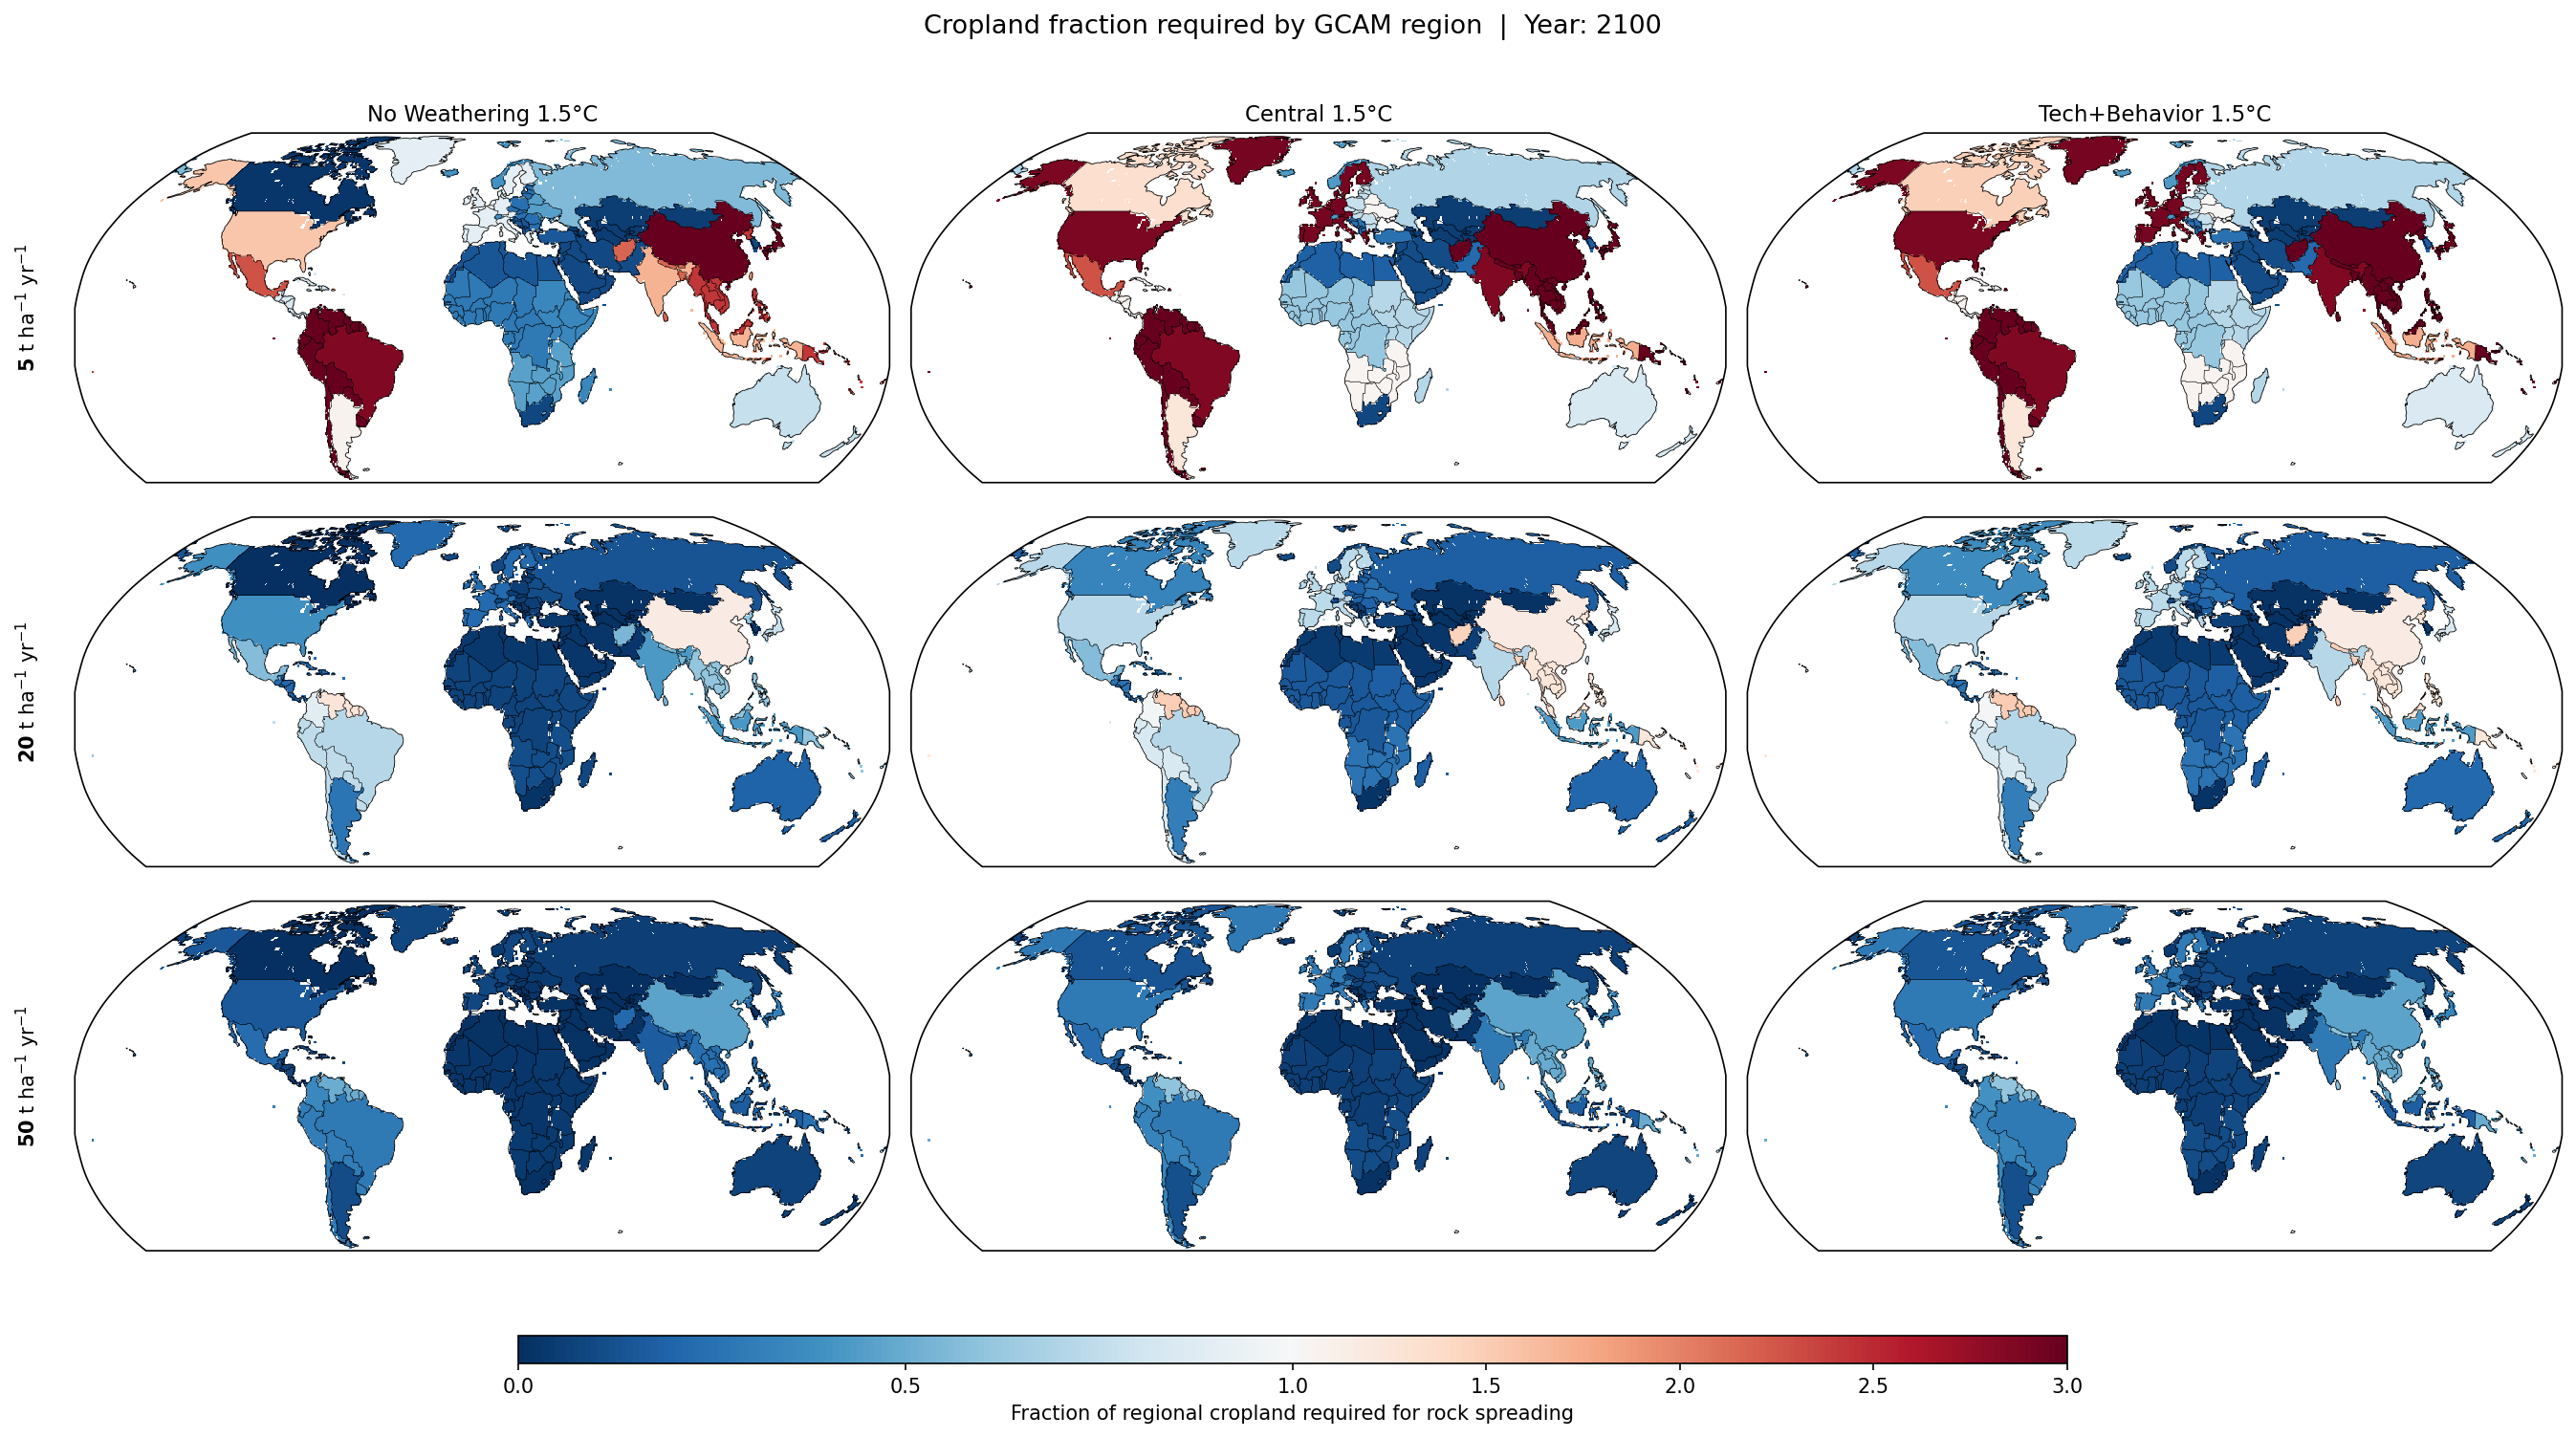

In [16]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
map_scenarios_cf = [
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
map_app_rates_cf = [5, 20, 50]   # three values from app_rates → 3 rows
map_year_cf      = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_cf    = "RdBu_r"   # blue < 1 (spare capacity), red > 1 (rate must be boosted)
vmin_cf      = 0.0
vcenter_cf   = 1.0
vmax_cf      = 3.0

fs_col_title_cf  = 11
fs_row_label_cf  = 10
fs_cbar_tick_cf  = 10
fs_cbar_label_cf = 10
fig_dpi_cf       = 150

lon_min_cf = -181;  lon_max_cf = 181
lat_min_cf =  -57;  lat_max_cf =  86

scen_labels_cf = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ plot — rows = fixed app rate, cols = scenario ]
# ============================================================
norm_cf = mcolors.TwoSlopeNorm(vmin=vmin_cf, vcenter=vcenter_cf, vmax=vmax_cf)

nrows = len(map_app_rates_cf)
ncols = len(map_scenarios_cf)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi_cf,
)

for row, apprate in enumerate(map_app_rates_cf):
    for col, scen in enumerate(map_scenarios_cf):
        ax = axes[row, col]

        frac_vals = (
            ds_regs["cropland_fraction_required"]
            .sel(scenario=scen, app_rate=apprate, time=map_year_cf)
            .values  # (n_reg_id,)
        )

        painted = paint_regions(dict(zip(ds_regs.reg_id.values, frac_vals)), reg_ids_np)
        painted_da = xr.DataArray(painted, dims=["y", "x"],
                                  coords={"y": ds.y, "x": ds.x})

        painted_da.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_cf,
            norm=norm_cf,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_cf, lon_max_cf, lat_min_cf, lat_max_cf],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels_cf.get(scen, scen), fontsize=fs_col_title_cf, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5,
                r"$\bf{" + str(int(apprate) if apprate == int(apprate) else apprate) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                transform=ax.transAxes,
                fontsize=fs_row_label_cf,
                va="center", ha="right", rotation=90,
            )

# shared colorbar
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(cmap=mycmap_cf, norm=norm_cf)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick_cf)
cbar.set_label("Fraction of regional cropland required for rock spreading",
               fontsize=fs_cbar_label_cf)

fig.suptitle(
    f"Cropland fraction required by GCAM region  |  Year: {map_year_cf}",
    fontsize=fs_col_title_cf + 2, y=1.01,
)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Rock application spatial footprint — densest-first cell selection

For each region, cells are selected in descending order of `cropland_frac` until their cumulative cropland area reaches `cropland_area_required_ha`. Selected cells are colored by their `cropland_frac`; unselected cells are transparent. Rows show how a lower prescribed rate spreads rock across a larger footprint to hit the same GCAM target.

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_22022/442898196.py:125: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


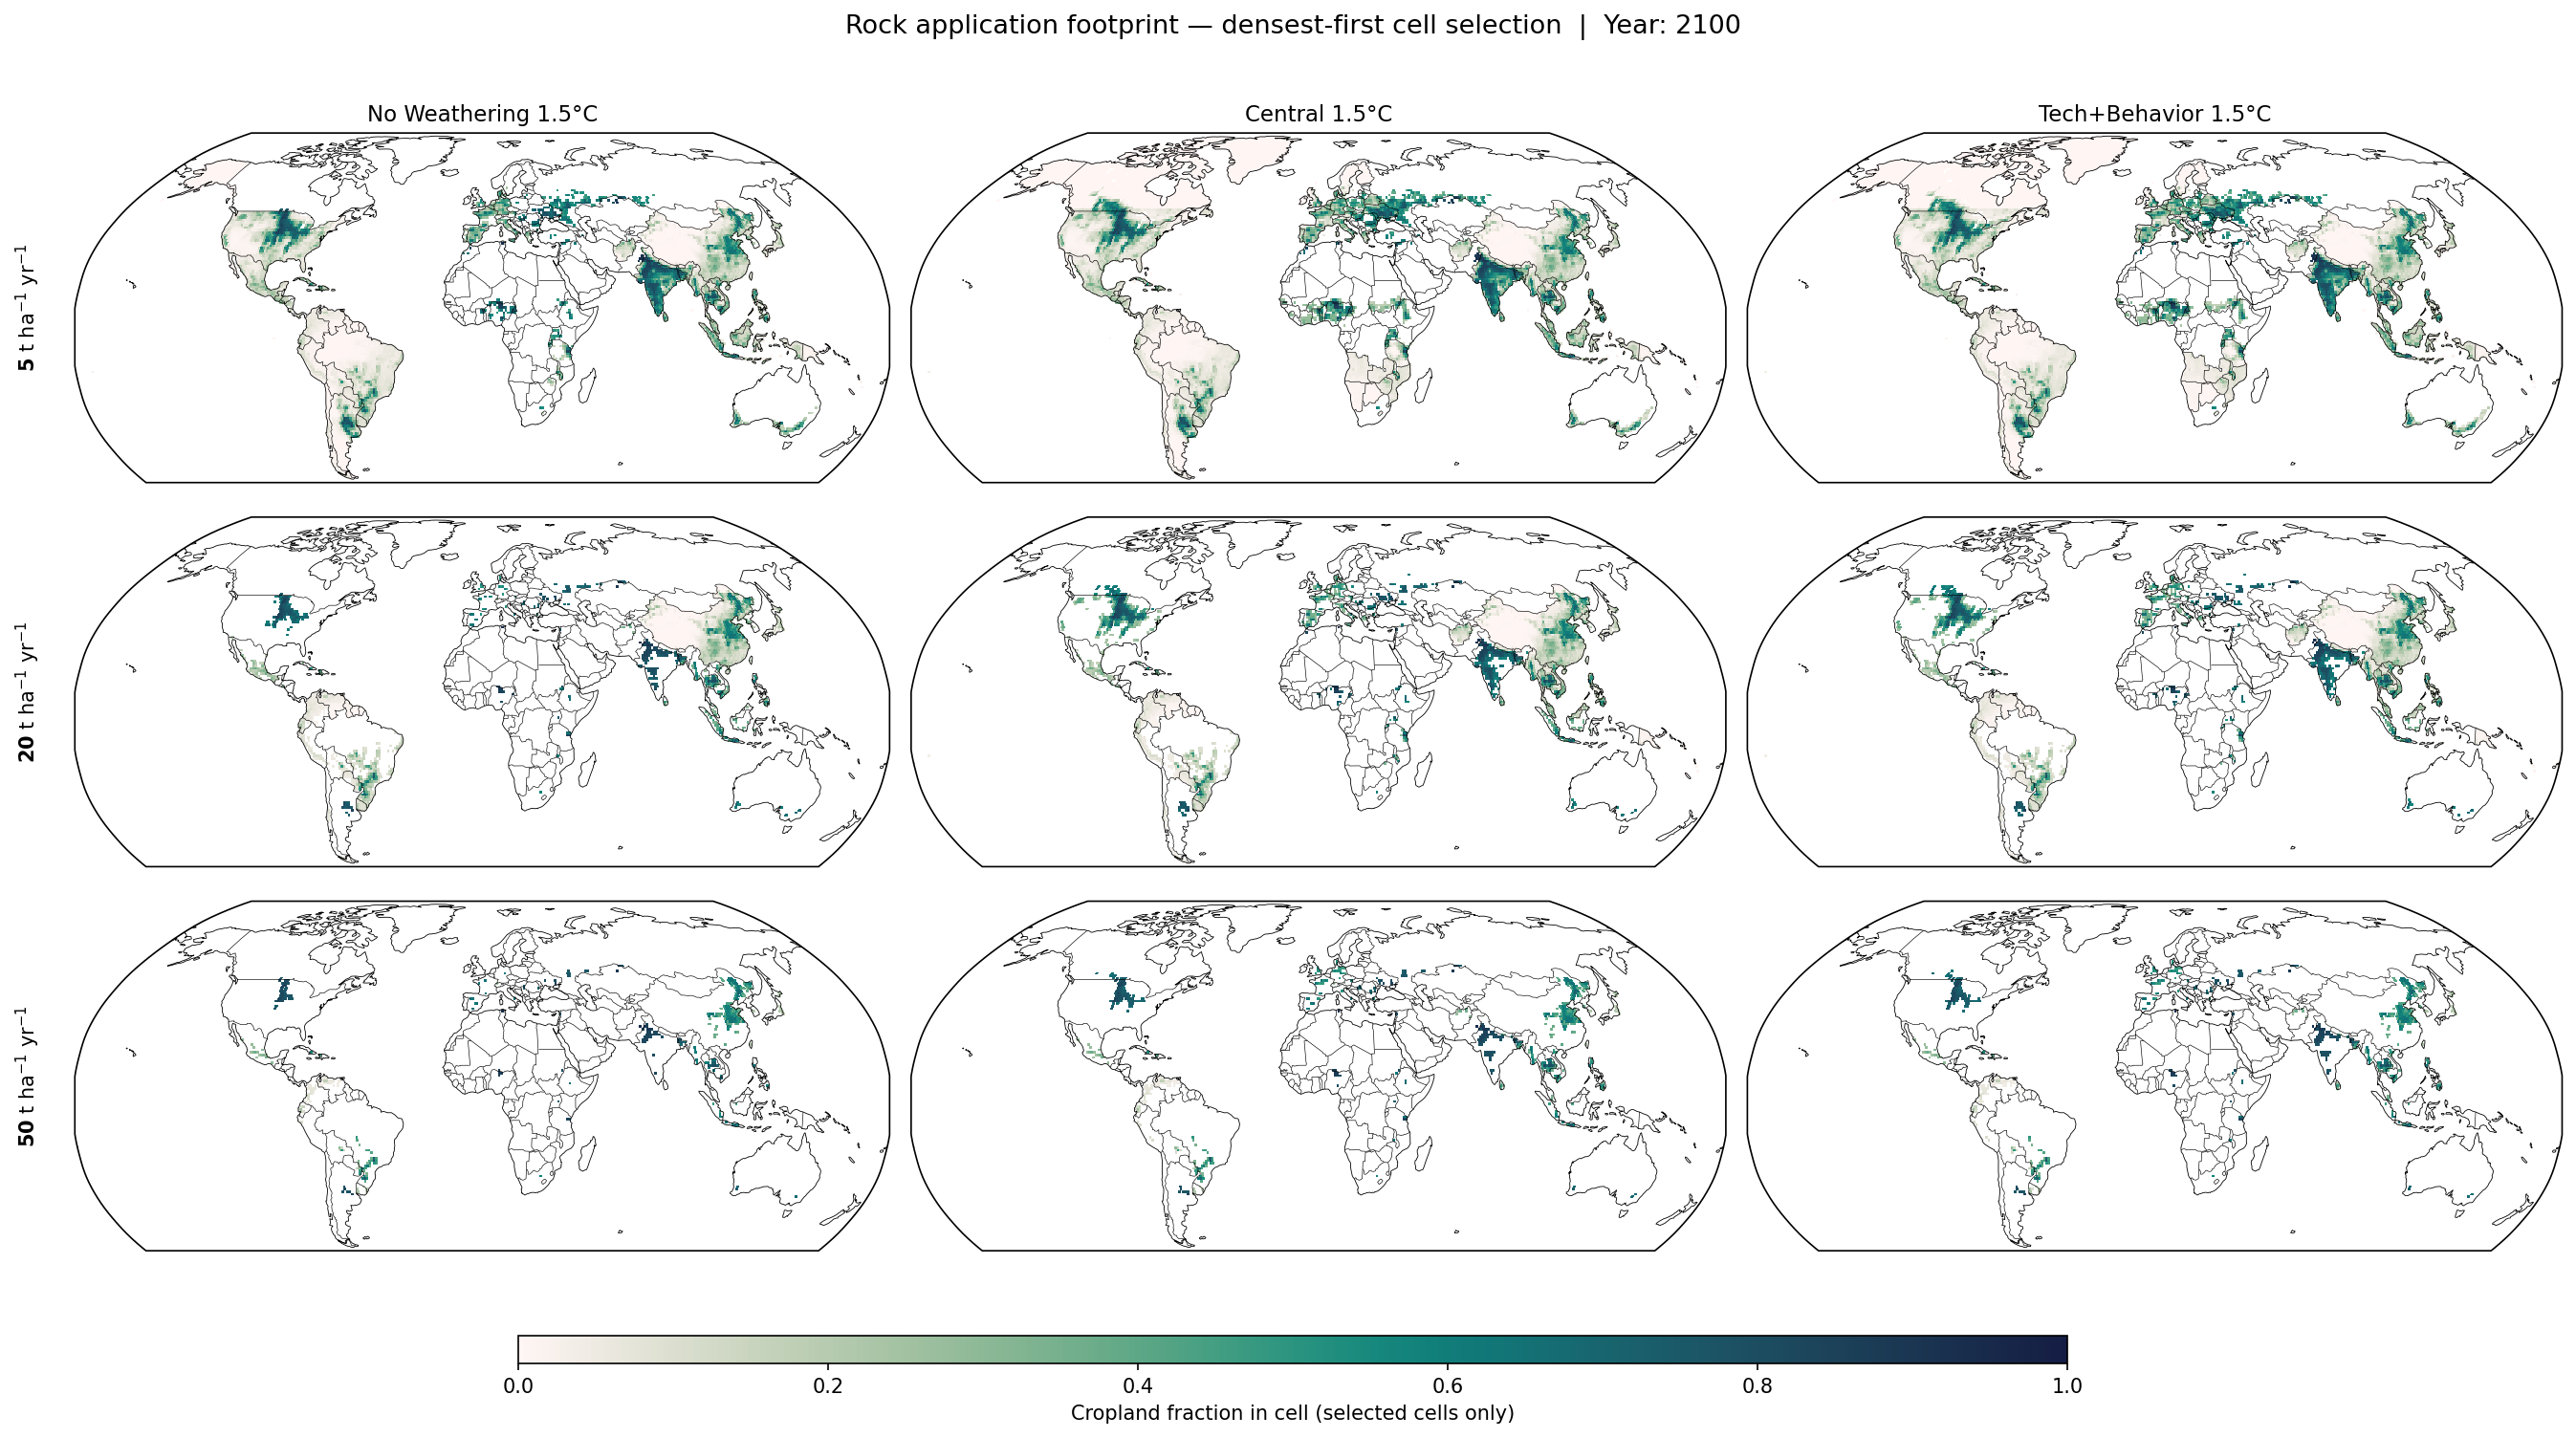

In [20]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
footprint_scenarios = [
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
footprint_app_rates = [5, 20, 50]   # three values from app_rates → 3 rows
footprint_year      = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_fp     = cmo.cm.tempo
vmin_fp       = 0.0
vmax_fp       = 1.0

fs_col_title_fp  = 11
fs_row_label_fp  = 10
fs_cbar_tick_fp  = 10
fs_cbar_label_fp = 10
fig_dpi_fp       = 150

lon_min_fp = -181;  lon_max_fp = 181
lat_min_fp =  -57;  lat_max_fp =  86

scen_labels_fp = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ static geographic fields — same across scenario and app_rate ]
# ============================================================
_fp_reg_ids_np     = ds["reg_id"].isel(scenario=0, app_rate=0).values.astype(int)
_fp_cropfrac_np    = ds["cropland_frac"].isel(scenario=0, app_rate=0).values
_fp_croparea_ha_np = ds["cropland_area"].isel(scenario=0, app_rate=0).values / 1e4  # m² → ha
_fp_unique_regs    = np.unique(_fp_reg_ids_np[_fp_reg_ids_np > 0])

# ============================================================
# [ plot ]
# ============================================================
nrows = len(footprint_app_rates)
ncols = len(footprint_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi_fp,
)

for row, apprate in enumerate(footprint_app_rates):
    for col, scen in enumerate(footprint_scenarios):
        ax = axes[row, col]

        # --- greedy cell selection for this panel
        sel_map = np.full(_fp_reg_ids_np.shape, np.nan)
        for reg in _fp_unique_regs:
            ys, xs = np.where(_fp_reg_ids_np == reg)
            if len(ys) == 0:
                continue
            target_ha = float(
                ds_regs["cropland_area_required_ha"]
                .sel(scenario=scen, app_rate=apprate, time=footprint_year, reg_id=reg)
                .values
            )
            if not np.isfinite(target_ha) or target_ha <= 0:
                continue

            frac_vals = np.nan_to_num(_fp_cropfrac_np[ys, xs], nan=0.0)
            area_vals = np.nan_to_num(_fp_croparea_ha_np[ys, xs], nan=0.0)

            order   = np.argsort(frac_vals)[::-1]
            cumarea = np.cumsum(area_vals[order])
            n = min(int(np.searchsorted(cumarea, target_ha, side="left")) + 1, len(order))

            sel = order[:n]
            sel_map[ys[sel], xs[sel]] = frac_vals[sel]

        da_fp = xr.DataArray(sel_map, dims=["y", "x"], coords={"y": ds.y, "x": ds.x})
        da_fp.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_fp,
            vmin=vmin_fp,
            vmax=vmax_fp,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_fp, lon_max_fp, lat_min_fp, lat_max_fp],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels_fp.get(scen, scen), fontsize=fs_col_title_fp, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5,
                r"$\bf{" + str(int(apprate) if apprate == int(apprate) else apprate) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                transform=ax.transAxes,
                fontsize=fs_row_label_fp,
                va="center", ha="right", rotation=90,
            )

# shared colorbar
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(
    cmap=mycmap_fp,
    norm=mcolors.Normalize(vmin=vmin_fp, vmax=vmax_fp),
)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick_fp)
cbar.set_label("Cropland fraction in cell (selected cells only)", fontsize=fs_cbar_label_fp)

fig.suptitle(
    f"Rock application footprint — densest-first cell selection  |  Year: {footprint_year}",
    fontsize=fs_col_title_fp + 2, y=1.01,
)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Rock application CDFs by global crop area

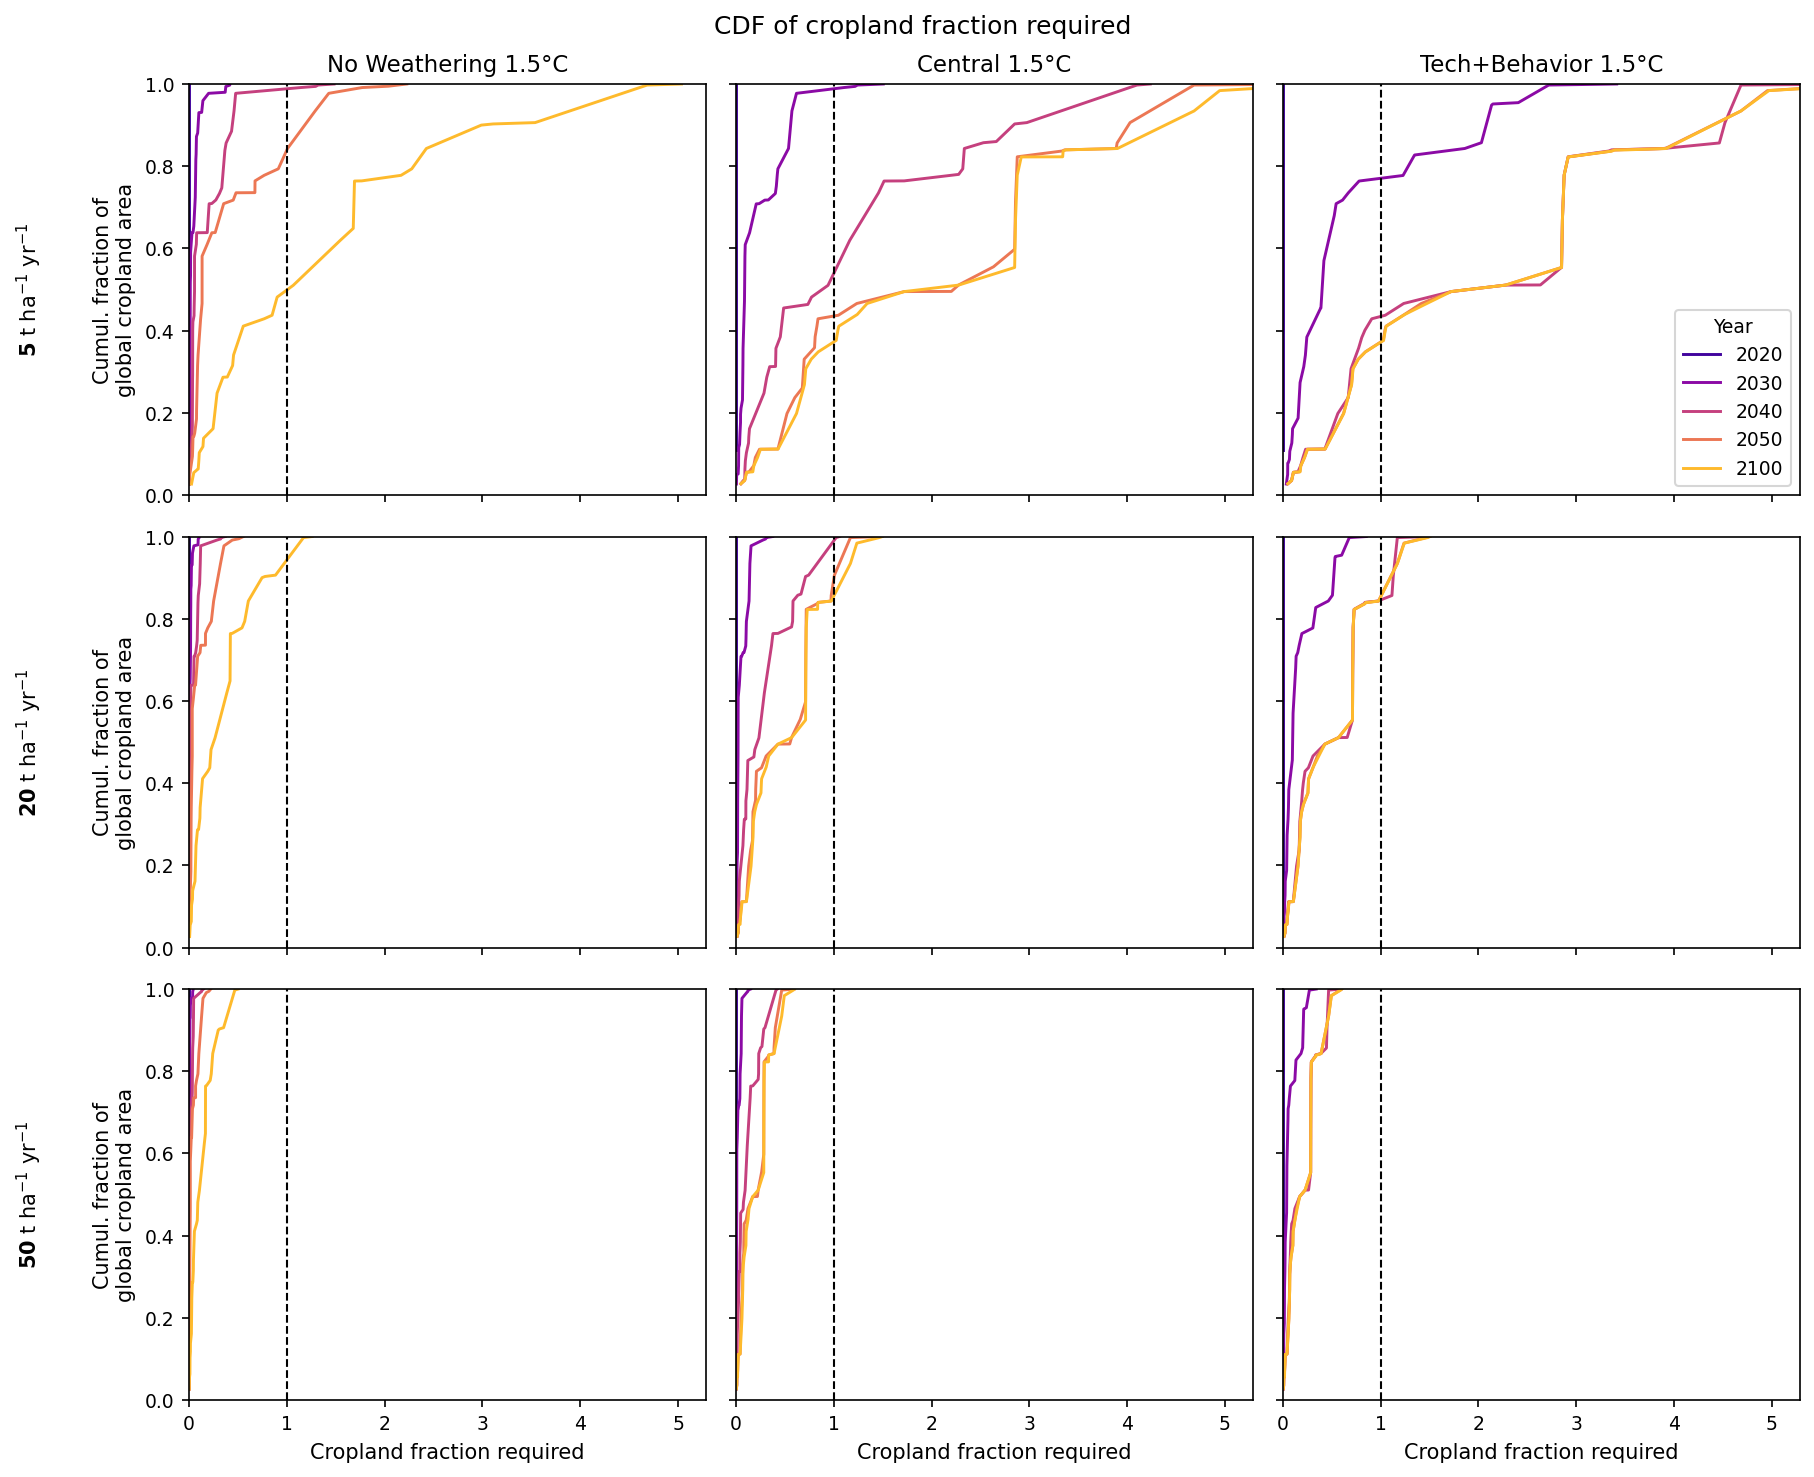

In [17]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
cdf_app_rates = [5, 20, 50]      # 3 app rates → 3 rows
cdf_scenarios = [                 # 3 scenarios → 3 columns
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
cdf_years = [2020, 2030, 2040, 2050, 2100]   # one line per year

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
fs_title      = 11
fs_row_label  = 10
fs_axis       = 10
fs_tick       = 9
fs_legend     = 9
fig_dpi       = 150
fig_width     = 12
fig_height    = 10

x_min = 0       # set to None for auto
x_max = None

scen_labels_cdf = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ plot ]
# _reg_area_ha and _total_global_cropland_ha defined in setup cell above
# ============================================================
year_colors = plt.cm.plasma(np.linspace(0.1, 0.85, len(cdf_years)))

nrows = len(cdf_app_rates)
ncols = len(cdf_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(fig_width, fig_height),
    dpi=fig_dpi,
    sharex=True, sharey=True,
)

for row, apprate in enumerate(cdf_app_rates):
    for col, scen in enumerate(cdf_scenarios):
        ax = axes[row, col]

        for yr, color in zip(cdf_years, year_colors):
            frac_req = (
                ds_regs["cropland_fraction_required"]
                .sel(scenario=scen, app_rate=apprate, time=yr)
                .values  # (n_reg_id,)
            )

            mask         = np.isfinite(frac_req) & (_reg_area_ha > 0)
            frac_valid   = frac_req[mask]
            area_valid   = _reg_area_ha[mask]

            sort_idx     = np.argsort(frac_valid)
            frac_sorted  = frac_valid[sort_idx]
            area_sorted  = area_valid[sort_idx]
            cum_area_frac = np.cumsum(area_sorted) / _total_global_cropland_ha

            ax.plot(frac_sorted, cum_area_frac, color=color, linewidth=1.4)

        # mark 100% cropland threshold
        ax.axvline(1.0, color="black", lw=1.0, ls="--", zorder=5)

        ax.set_ylim(0, 1)
        if x_min is not None:
            ax.set_xlim(left=x_min)
        if x_max is not None:
            ax.set_xlim(right=x_max)
        ax.tick_params(labelsize=fs_tick)

        if row == 0:
            ax.set_title(scen_labels_cdf.get(scen, scen), fontsize=fs_title, pad=6)

        if row == nrows - 1:
            ax.set_xlabel("Cropland fraction required", fontsize=fs_axis)

        if col == 0:
            ax.set_ylabel("Cumul. fraction of\nglobal cropland area", fontsize=fs_axis)

        if col == 0:
            ax.annotate(
                r"$\bf{" + str(int(apprate) if apprate == int(apprate) else apprate) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                xy=(-0.28, 0.5), xycoords="axes fraction",
                fontsize=fs_row_label, va="center", ha="right", rotation=90,
            )

# legend on top-right panel
handles = [
    plt.Line2D([0], [0], color=c, linewidth=1.4, label=str(yr))
    for yr, c in zip(cdf_years, year_colors)
]
axes[0, -1].legend(handles=handles, title="Year", fontsize=fs_legend,
                   title_fontsize=fs_legend, frameon=True)

fig.suptitle("CDF of cropland fraction required", fontsize=fs_title + 1)
plt.tight_layout()
plt.show()

## Distribution of cropland fraction required

Violin plots of `cropland_fraction_required` across GCAM regions for a selected scenario and three fixed application rates. Each point is one GCAM region. The dashed line at 1.0 marks where a region needs more than its full cropland area — above this the rate is automatically boosted.

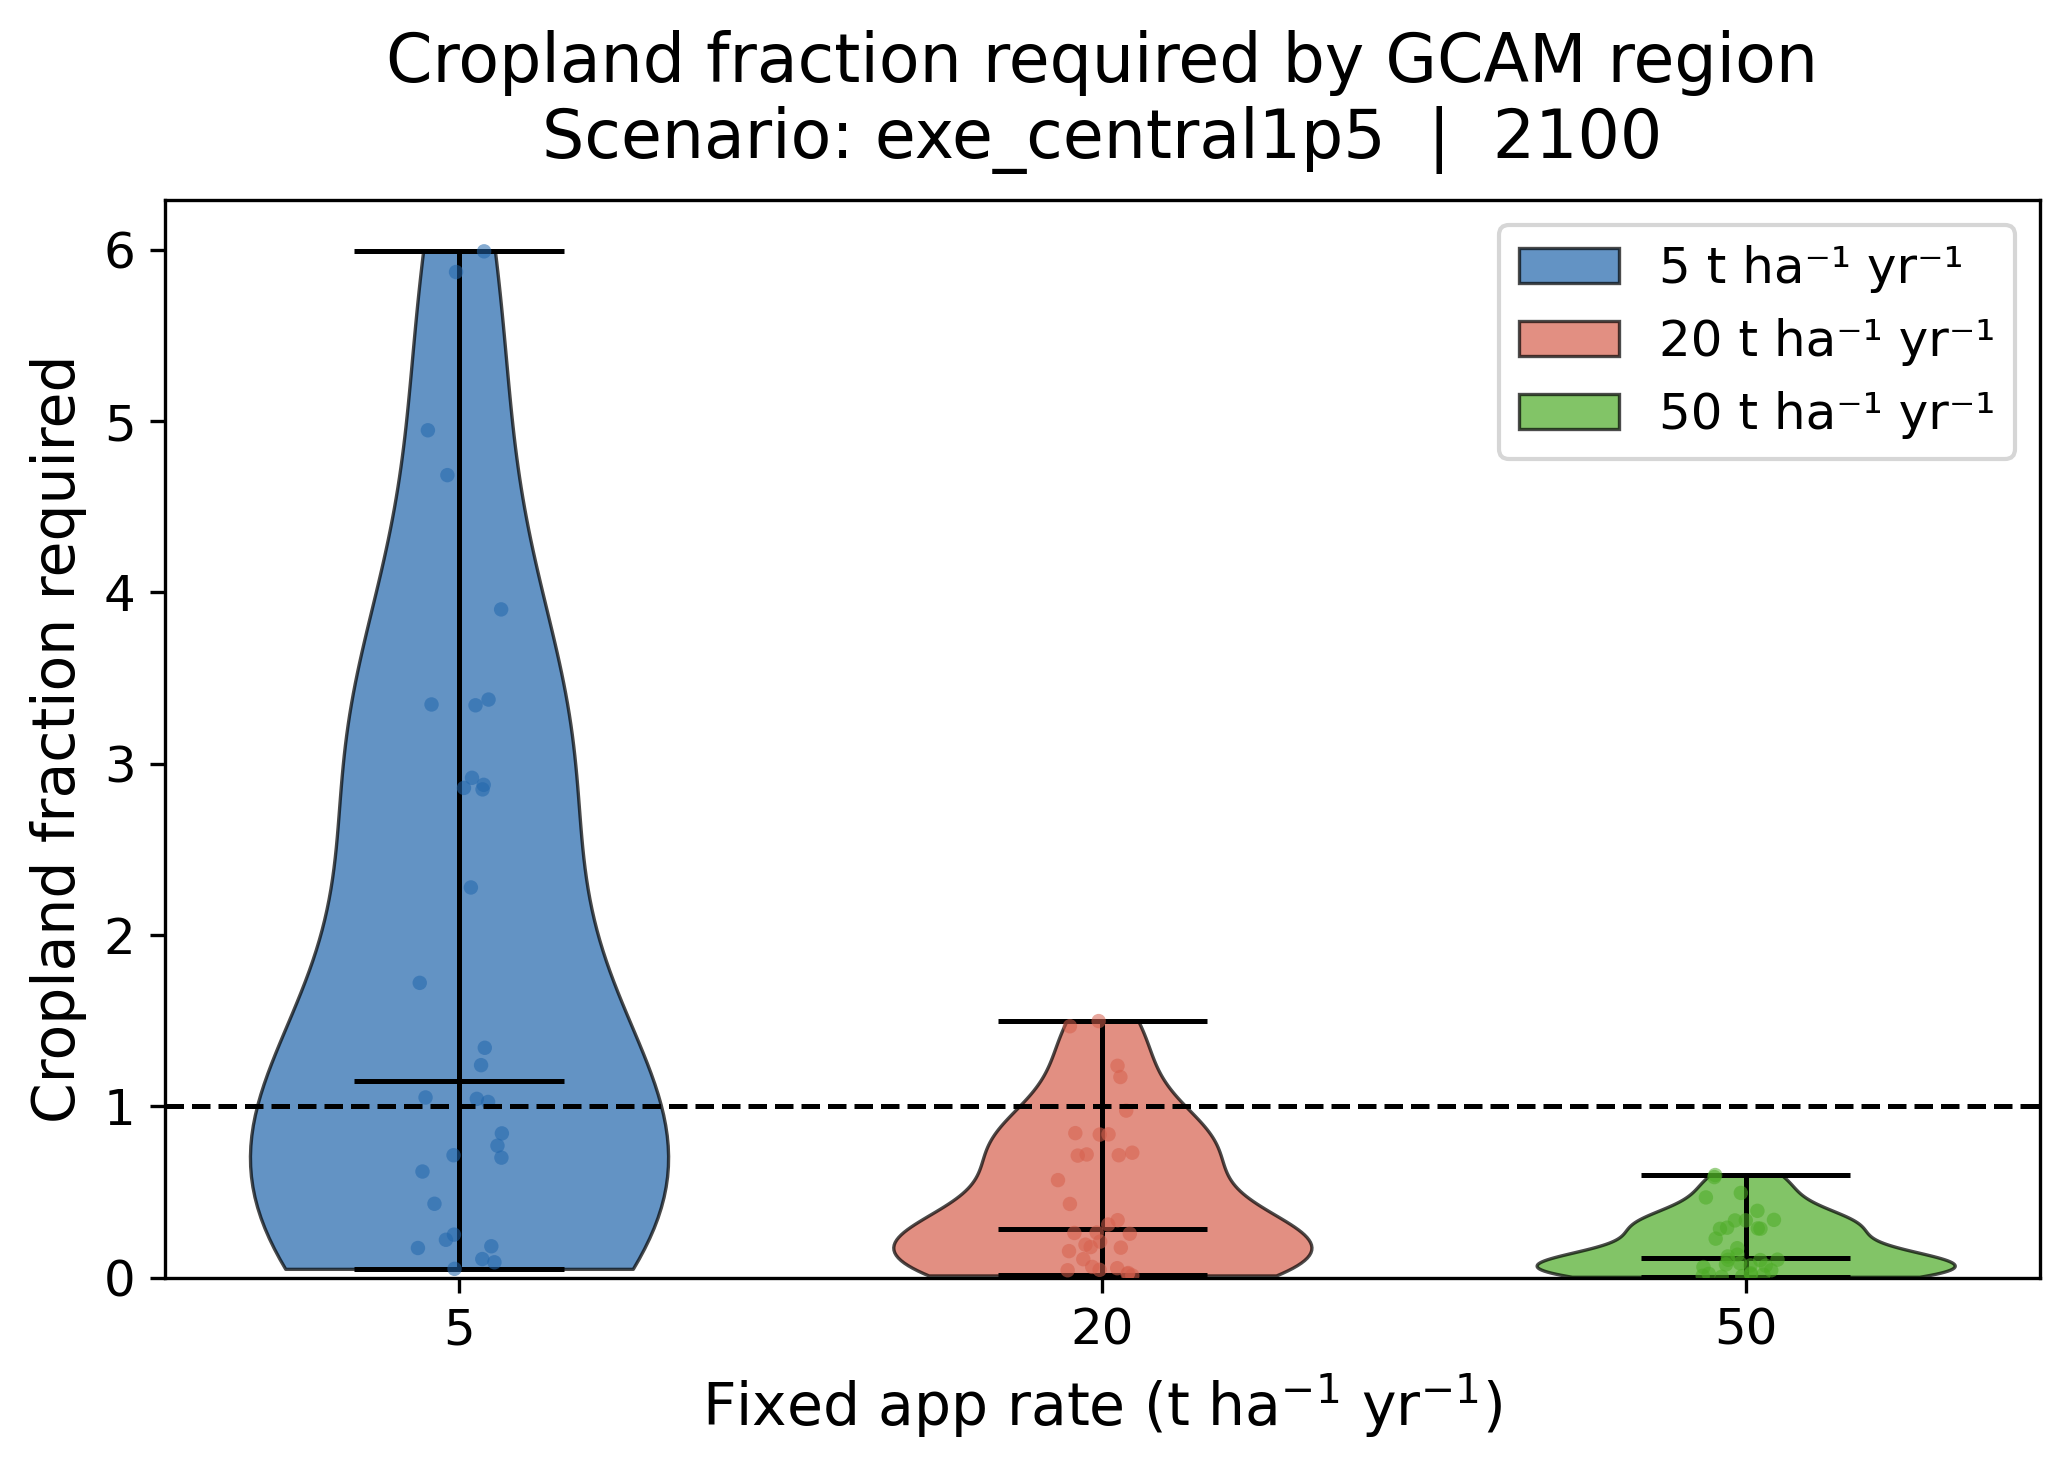

In [18]:
# ============================================================
# [ aesthetics — edit here ]
# ============================================================
fs_title      = 16
fs_axis_label = 14
fs_tick       = 12
fs_legend     = 12

violin_colors = ["#2166ac", "#d6604d", "#4dac26"]
violin_alpha  = 0.7
violin_width  = 0.65

show_median   = True
line_color    = "black"
line_width    = 1.2

show_points   = True
point_alpha   = 0.55
point_size    = 12
point_jitter  = 0.07

fig_width  = 7
fig_height = 5
fig_dpi    = 300

y_min = 0
y_max = None

# ============================================================
# [ user selections — edit here ]
# ============================================================
selected_scenario  = "exe_central1p5"
selected_app_rates = [5, 20, 50]   # three values from app_rates
selected_year      = 2100

# ============================================================
# [ build violin data from ds_regs ]
# each point = one GCAM region; values come directly from the pkl
# ============================================================
time_label = str(selected_year)
da_scen = (
    ds_regs["cropland_fraction_required"]
    .sel(scenario=selected_scenario, time=selected_year)
)  # → (app_rate, reg_id)

violin_data = []
for apprate in selected_app_rates:
    vals = da_scen.sel(app_rate=apprate).values  # (n_reg_id,)
    vals = vals[np.isfinite(vals) & (vals > 0)]
    violin_data.append(vals.tolist())

# ============================================================
# [ plot ]
# ============================================================
rng = np.random.default_rng(42)
positions = np.arange(1, len(selected_app_rates) + 1)

fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=fig_dpi)

parts = ax.violinplot(
    violin_data,
    positions=positions,
    widths=violin_width,
    showmedians=show_median,
    showextrema=True,
)

for pc, color in zip(parts["bodies"], violin_colors):
    pc.set_facecolor(color)
    pc.set_alpha(violin_alpha)
    pc.set_edgecolor(line_color)
    pc.set_linewidth(0.8)

for key in ("cmedians", "cmins", "cmaxes", "cbars"):
    parts[key].set_edgecolor(line_color)
    parts[key].set_linewidth(line_width)

if show_points:
    for vals, pos, color in zip(violin_data, positions, violin_colors):
        jitter = rng.uniform(-point_jitter, point_jitter, size=len(vals))
        ax.scatter(
            pos + jitter, vals,
            color=color, alpha=point_alpha, s=point_size,
            zorder=3, edgecolors="none",
        )

# 100% cropland threshold
ax.axhline(1.0, color="black", lw=1.2, ls="--", zorder=5)

ax.set_xticks(positions)
ax.set_xticklabels([
    str(int(ar) if ar == int(ar) else ar) for ar in selected_app_rates
], fontsize=fs_tick)
ax.set_xlabel(r"Fixed app rate (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_axis_label)
ax.set_ylabel("Cropland fraction required", fontsize=fs_axis_label)
ax.set_title(
    f"Cropland fraction required by GCAM region\n"
    f"Scenario: {selected_scenario}  |  {time_label}",
    fontsize=fs_title, pad=10,
)
ax.tick_params(axis="both", labelsize=fs_tick)

if y_min is not None:
    ax.set_ylim(bottom=y_min)
if y_max is not None:
    ax.set_ylim(top=y_max)

legend_handles = [
    mpatches.Patch(facecolor=c, alpha=violin_alpha, edgecolor=line_color,
                   linewidth=0.8, label=f"{int(ar) if ar == int(ar) else ar} t ha⁻¹ yr⁻¹")
    for c, ar in zip(violin_colors, selected_app_rates)
]
ax.legend(handles=legend_handles, fontsize=fs_legend, frameon=True)

plt.tight_layout()
plt.savefig(f"violin_cropfrac_{selected_scenario}_{time_label}.png", dpi=fig_dpi, bbox_inches="tight")
plt.show()

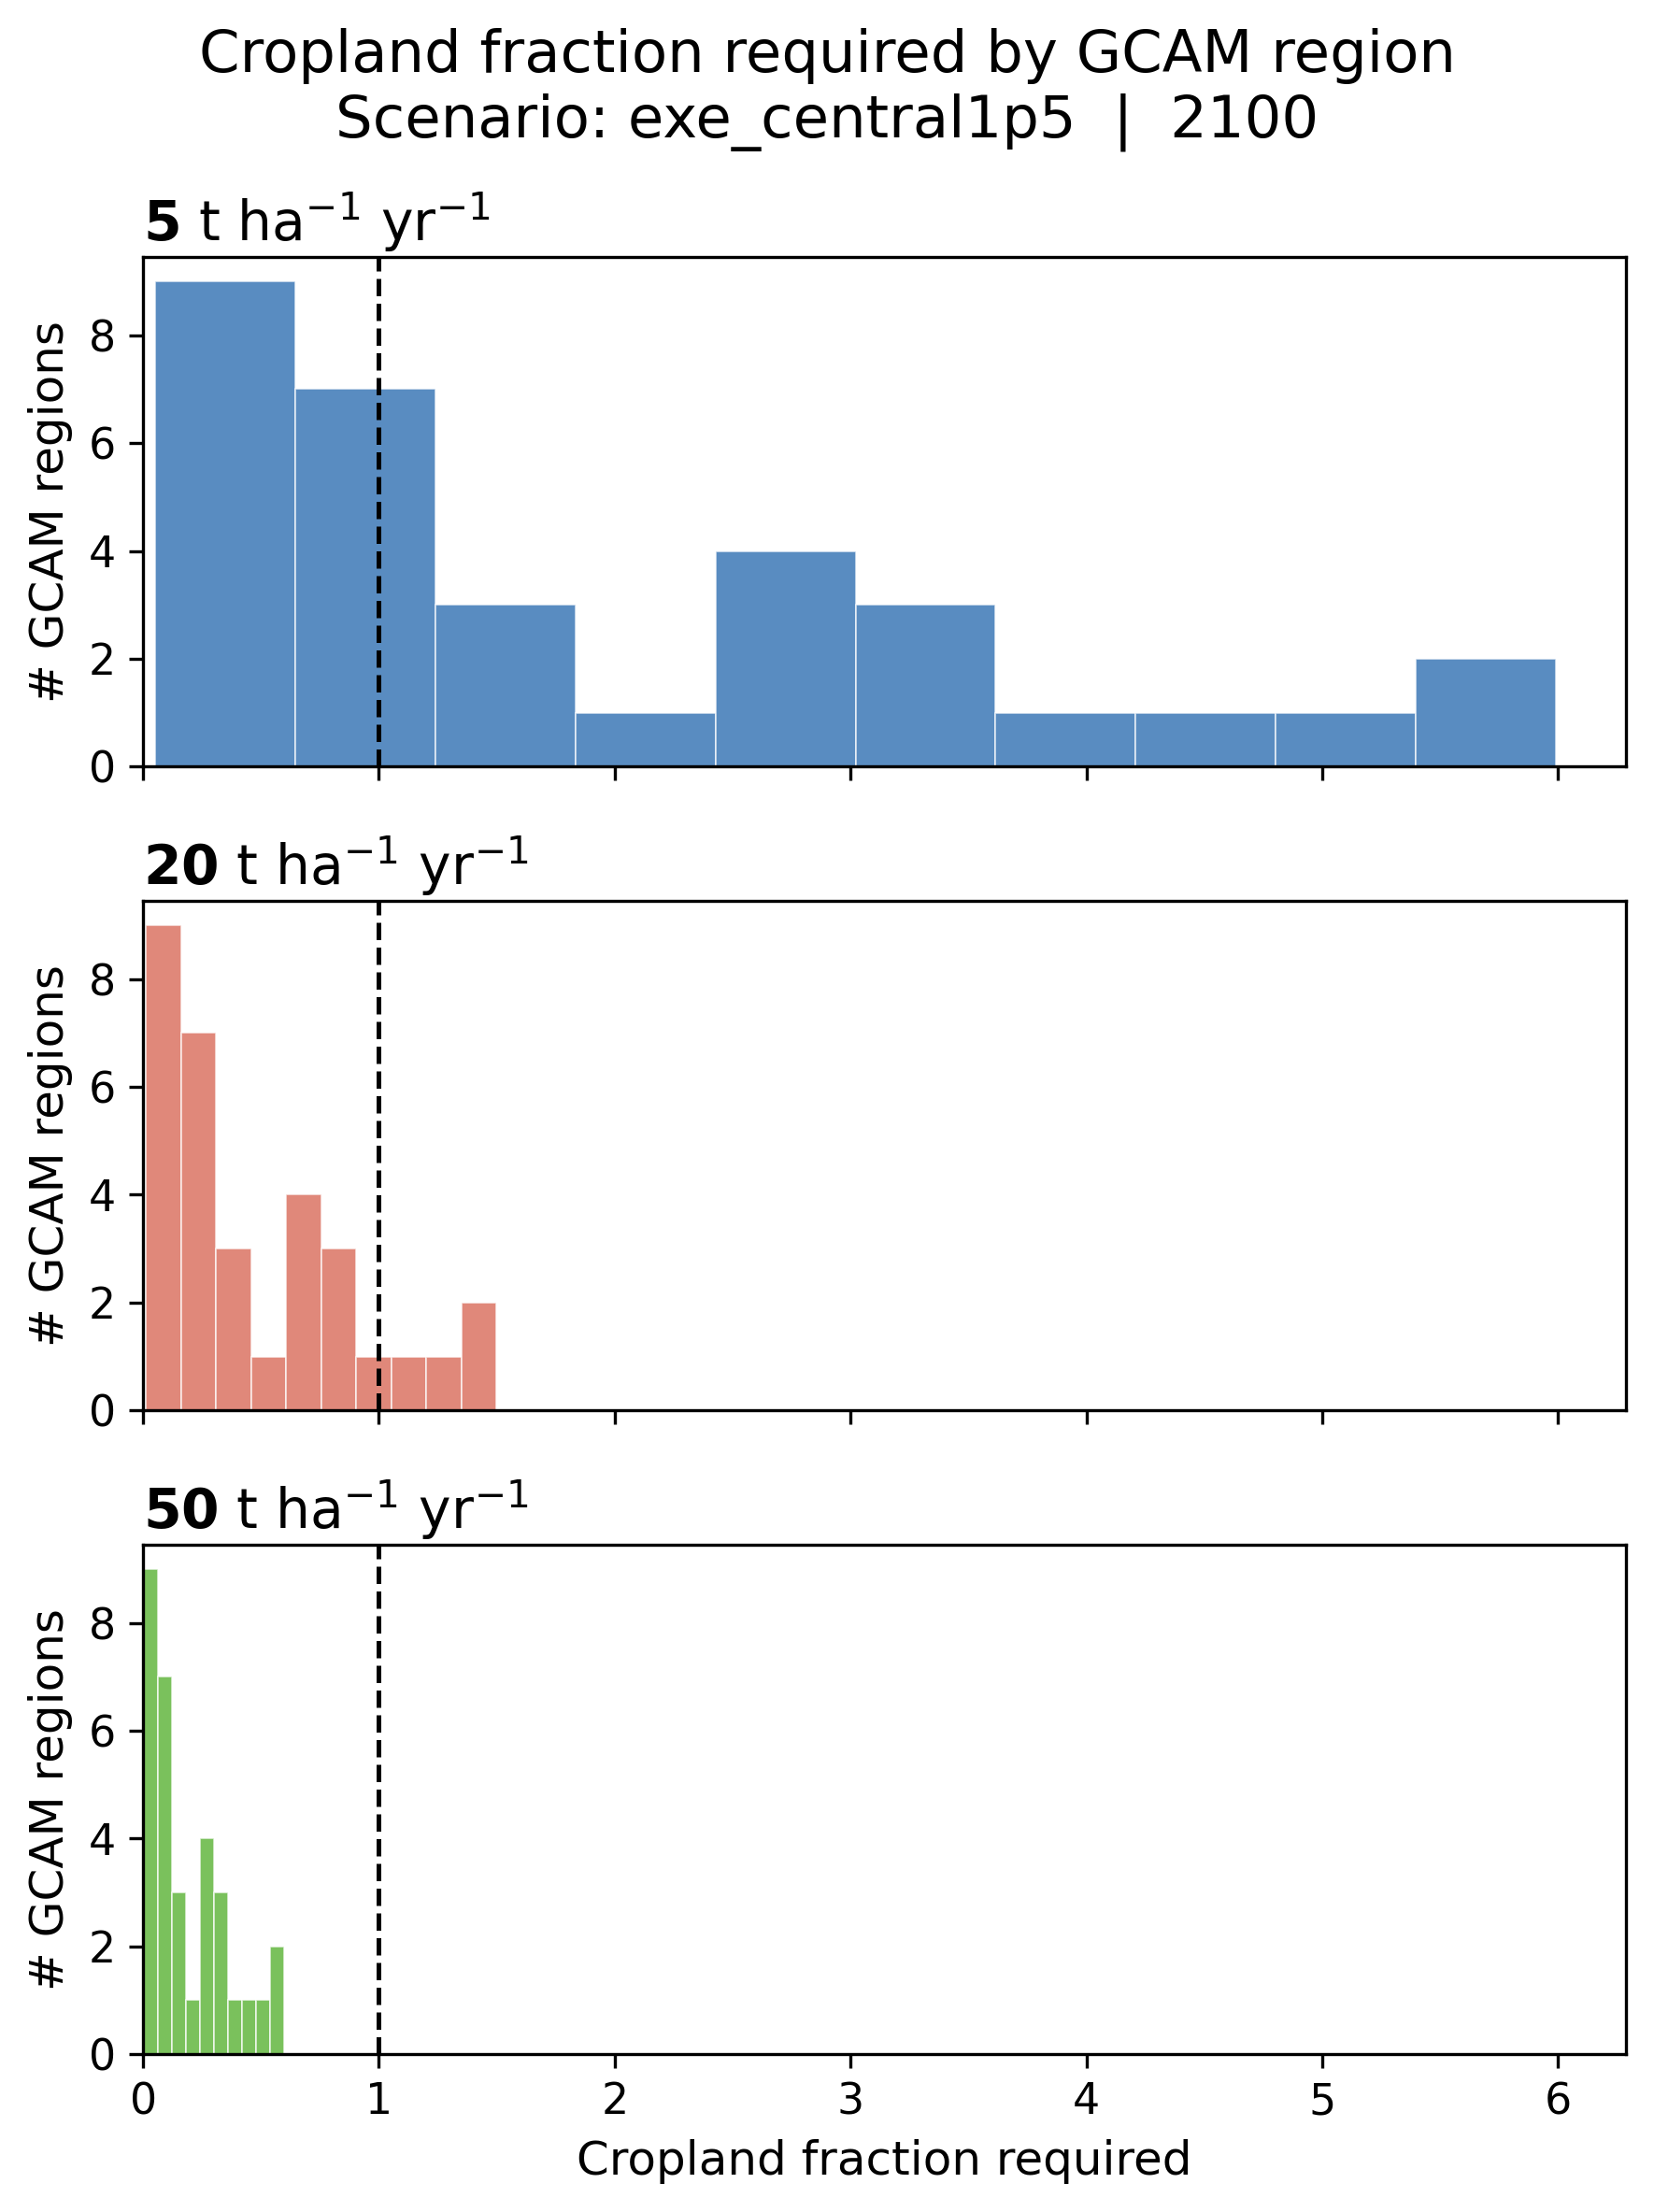

In [19]:
# ============================================================
# [ aesthetics — edit here ]
# ============================================================
fs_title       = 14
fs_axis_label  = 12
fs_tick        = 11

hist_colors    = ["#2166ac", "#d6604d", "#4dac26"]
hist_alpha     = 0.75
hist_edgecolor = "white"
hist_linewidth = 0.4
hist_n_bins    = 10

fig_width  = 6
fig_height = 8
fig_dpi    = 300

x_min = 0
x_max = None

# ============================================================
# [ user selections — edit here ]
# ============================================================
selected_scenario  = "exe_central1p5"
selected_app_rates = [5, 20, 50]   # three values from app_rates
selected_year      = 2100

# ============================================================
# [ build histogram data from ds_regs ]
# ============================================================
time_label_h = str(selected_year)
da_scen_h = (
    ds_regs["cropland_fraction_required"]
    .sel(scenario=selected_scenario, time=selected_year)
)  # → (app_rate, reg_id)

hist_data = []
for apprate in selected_app_rates:
    vals = da_scen_h.sel(app_rate=apprate).values  # (n_reg_id,)
    vals = vals[np.isfinite(vals) & (vals > 0)]
    hist_data.append(vals.tolist())

# ============================================================
# [ plot — three stacked subplots, one per app rate ]
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(fig_width, fig_height), dpi=fig_dpi, sharex=True)

for ax, vals, apprate, color in zip(axes, hist_data, selected_app_rates, hist_colors):
    ax.hist(
        vals,
        bins=hist_n_bins,
        color=color,
        alpha=hist_alpha,
        edgecolor=hist_edgecolor,
        linewidth=hist_linewidth,
    )
    ax.axvline(1.0, color="black", lw=1.2, ls="--", zorder=5)
    ax.set_ylabel("# GCAM regions", fontsize=fs_axis_label)
    ax.tick_params(axis="both", labelsize=fs_tick)
    label = str(int(apprate) if apprate == int(apprate) else apprate)
    ax.set_title(r"$\bf{" + label + r"}$ t ha$^{-1}$ yr$^{-1}$", fontsize=fs_title, loc="left", pad=4)
    if x_min is not None:
        ax.set_xlim(left=x_min)
    if x_max is not None:
        ax.set_xlim(right=x_max)

axes[-1].set_xlabel("Cropland fraction required", fontsize=fs_axis_label)
fig.suptitle(
    f"Cropland fraction required by GCAM region\n"
    f"Scenario: {selected_scenario}  |  {time_label_h}",
    fontsize=fs_title + 1,
)

plt.tight_layout()
plt.show()

## Regional time series: effective rate and effective cropland fraction

Six panels (3 rows × 2 columns). Each row is a fixed application rate; left column shows the effective application rate over time per GCAM region, right column shows the effective cropland fraction (capped at 1.0). The dashed line in the left panels marks the prescribed rate — regions above it have been boosted. The dashed line in the right panels marks the 100% cropland ceiling.

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_22022/1089664745.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_reg  = plt.cm.get_cmap("nipy_spectral", len(ds_regs.reg_id))


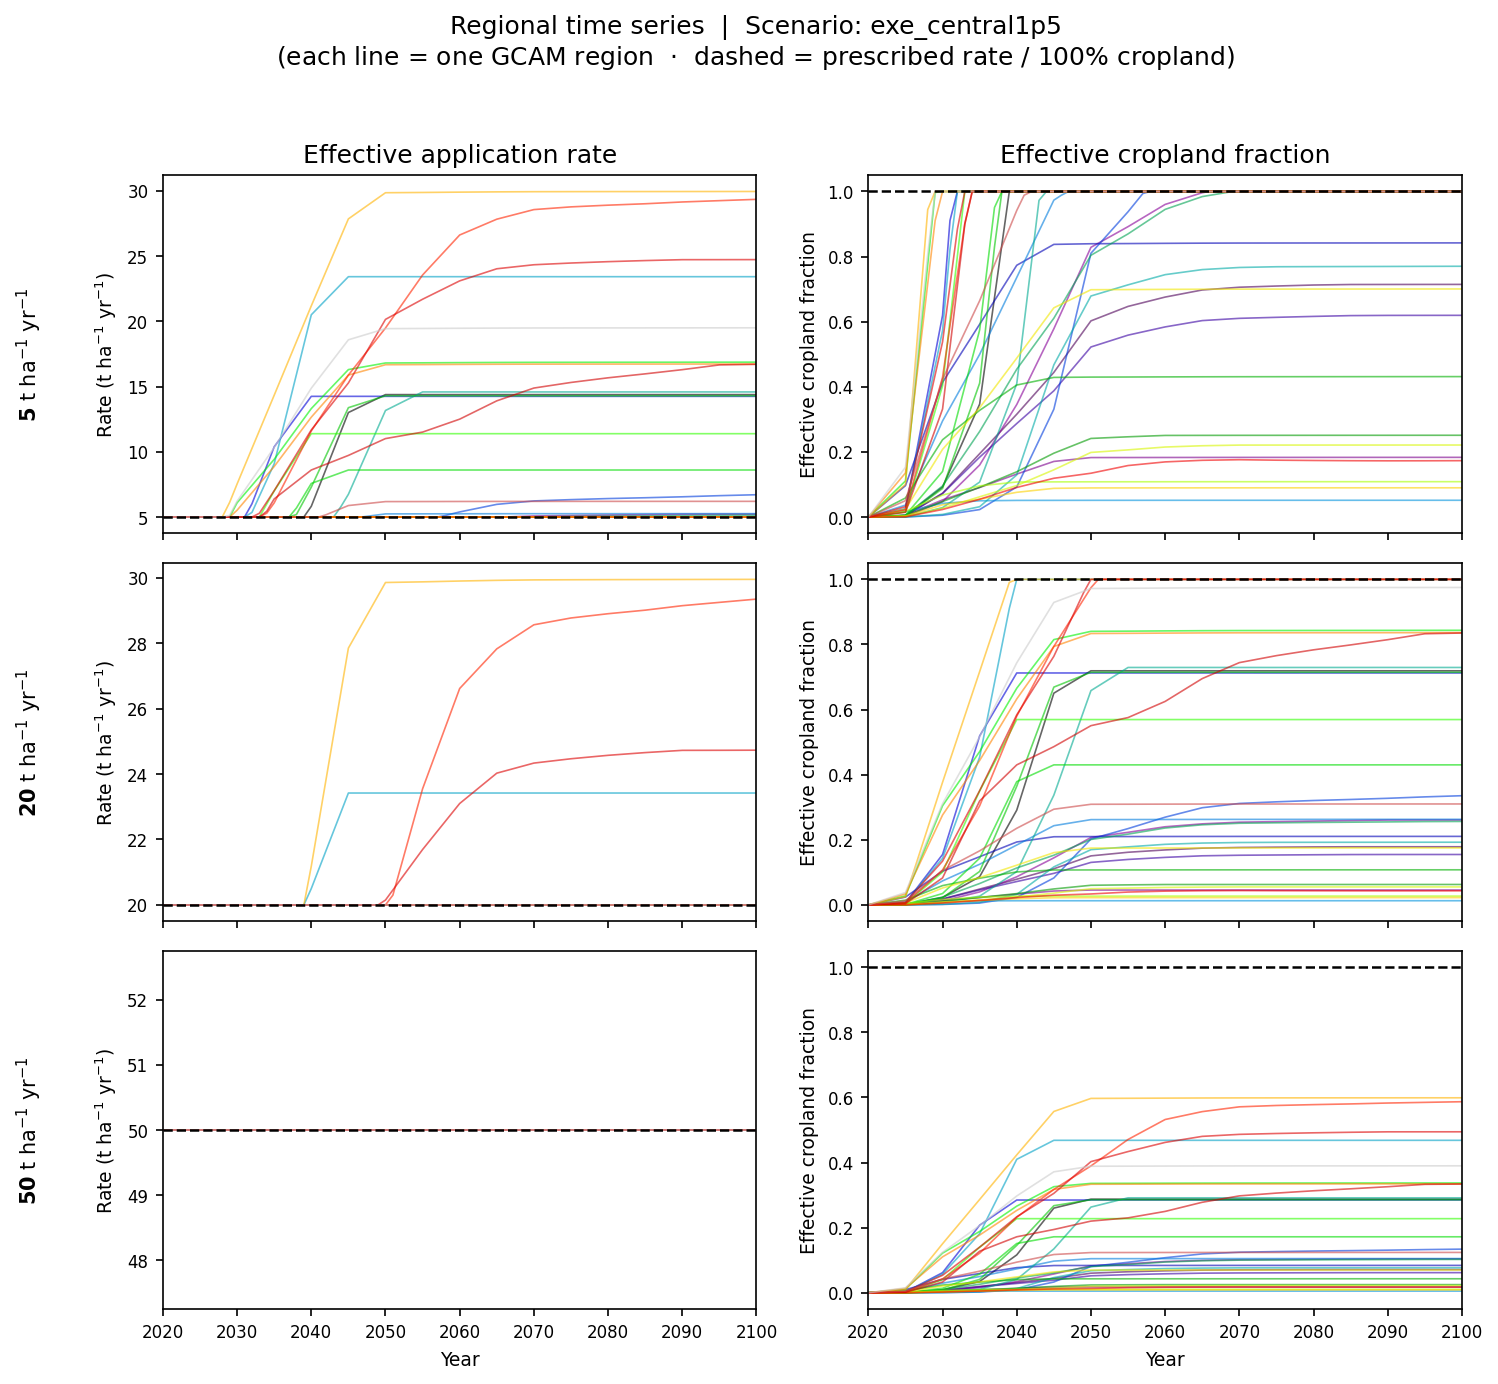

In [22]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
ts6_scenario  = "exe_central1p5"
ts6_app_rates = [5, 20, 50]   # 3 app rates → 3 rows

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
cmap_reg  = plt.cm.get_cmap("nipy_spectral", len(ds_regs.reg_id))
lw_reg    = 0.8
alpha_reg = 0.6

hline_color = "black"
hline_lw    = 1.2
hline_ls    = "--"

fs_col_title = 12
fs_row_label = 10
fs_axis      = 9
fs_tick      = 8
fig_dpi      = 150

# ============================================================
# [ plot ]
# ============================================================
times_reg    = ds_regs.time.values
reg_ids_list = ds_regs.reg_id.values

nrows = len(ts6_app_rates)
ncols = 2

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(10, 3 * nrows),
    dpi=fig_dpi,
    sharex=True,
)

for row, apprate in enumerate(ts6_app_rates):
    ax_rate = axes[row, 0]
    ax_frac = axes[row, 1]

    # left: effective application rate from pkl
    rate_pivot = (
        df_by_scen_ar[ts6_scenario][apprate]
        .pivot(index="time", columns="reg_id", values="rockflx_t_ha")
        .reindex(index=times_reg, columns=reg_ids_list)
    )

    # right: effective cropland fraction (capped at 1.0)
    frac_da = ds_regs["cropland_fraction_effective"].sel(
        scenario=ts6_scenario, app_rate=apprate
    )  # (time, reg_id)

    for i, rid in enumerate(reg_ids_list):
        color = cmap_reg(i)
        ax_rate.plot(times_reg, rate_pivot[rid].values,
                     color=color, lw=lw_reg, alpha=alpha_reg)
        ax_frac.plot(times_reg, frac_da.sel(reg_id=rid).values,
                     color=color, lw=lw_reg, alpha=alpha_reg)

    # reference lines
    ax_rate.axhline(apprate, color=hline_color, lw=hline_lw, ls=hline_ls, zorder=5)
    ax_frac.axhline(1.0,     color=hline_color, lw=hline_lw, ls=hline_ls, zorder=5)

    # axis labels
    ax_rate.set_ylabel(r"Rate (t ha$^{-1}$ yr$^{-1}$)",  fontsize=fs_axis)
    ax_frac.set_ylabel("Effective cropland fraction", fontsize=fs_axis)

    for ax in (ax_rate, ax_frac):
        ax.set_xlim(times_reg[0], times_reg[-1])
        ax.tick_params(labelsize=fs_tick)

    # row label on left margin
    label = str(int(apprate) if apprate == int(apprate) else apprate)
    ax_rate.annotate(
        r"$\bf{" + label + r"}$ t ha$^{-1}$ yr$^{-1}$",
        xy=(-0.2, 0.5), xycoords="axes fraction",
        fontsize=fs_row_label, va="center", ha="right", rotation=90,
    )

# column titles
axes[0, 0].set_title("Effective application rate",  fontsize=fs_col_title)
axes[0, 1].set_title("Effective cropland fraction", fontsize=fs_col_title)

# x-axis label on bottom row only
axes[-1, 0].set_xlabel("Year", fontsize=fs_axis)
axes[-1, 1].set_xlabel("Year", fontsize=fs_axis)

fig.suptitle(
    f"Regional time series  |  Scenario: {ts6_scenario}\n"
    r"(each line = one GCAM region  $\cdot$  dashed = prescribed rate / 100% cropland)",
    fontsize=fs_col_title, y=1.02,
)
plt.tight_layout()
plt.show()

# SCRATCH -------------------